In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

expectation of data

In [2]:

PROJECT_ROOT = Path.cwd().parent
print(PROJECT_ROOT)
DATA_PATH = PROJECT_ROOT / "student_mental_health.csv"


if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset introuvable : {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Dataset chargé avec succès.")
print("Dimensions :", df.shape)

c:\Users\Youcode\Desktop\2eme année IA\projet_soutenance_croisée
Dataset chargé avec succès.
Dimensions : (2000, 17)


In [3]:
print("premiere  lignes :")
display(df.head())

print("dernieres lignes :")
display(df.tail())

premiere  lignes :


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


dernieres lignes :


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


In [4]:
print("Informations generale :")
df.info()

print("\nNoms des colonnes :")
print(df.columns.tolist())

print("\nTypes des variables :")
display(df.dtypes.to_frame(name="Type"))

Informations generale :
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate      

,Type
Student_ID,str
Age,int64
Gender,str
Year_of_Study,int64
Sleep_Hours,float64
Study_Hours_Per_Week,float64
GPA,float64
Social_Media_Hours,float64
Screen_Time_Hours,float64
Physical_Activity,str


verifier les valeur manquant et doublants

In [5]:
missing_values = df.isnull().sum()
print(missing_values)

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


In [6]:
print("nombre des ligne duplique :", df.duplicated().sum())
print("nombre total de valeurs manquantes :", df.isnull().sum().sum())

nombre des ligne duplique : 0
nombre total de valeurs manquantes : 419


la partie EDA

In [7]:
print("statistique des variables numeriques :")
display(df.describe().T)



statistique des variables numeriques :


,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


separation des valeur numeric ou categorielle 

In [8]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()


categorical_columns.remove('Student_ID')
print("Variables numeriques :", numeric_columns)
print("\nVariables categorielle  :", categorical_columns)

Variables numeriques : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Variables categorielle  : ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


C:\Users\Youcode\AppData\Local\Temp\ipykernel_33564\4201895245.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()


In [9]:
for column in categorical_columns:

    print(f"\nColonne : {column}")
    print("Valeurs différentes :")
    print(df[column].value_counts(dropna=False))


Colonne : Gender
Valeurs différentes :
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Colonne : Physical_Activity
Valeurs différentes :
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Colonne : Part_Time_Job
Valeurs différentes :
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Colonne : Diet_Quality
Valeurs différentes :
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

Colonne : Previous_Mental_Health_History
Valeurs différentes :
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Colonne : Mental_Health_Risk
Valeurs différentes :
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


distribution des varibale numerique 

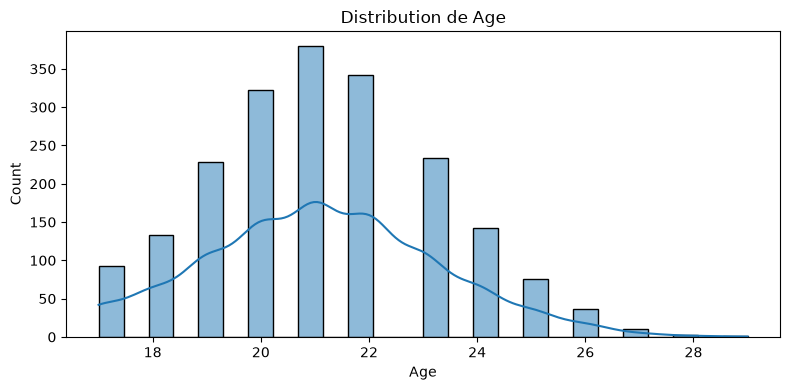

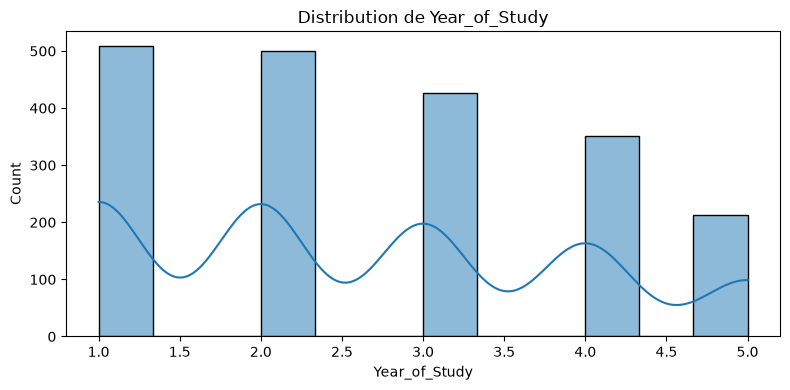

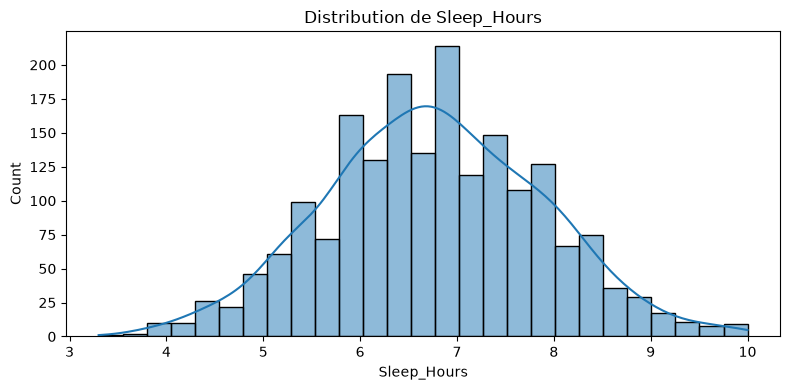

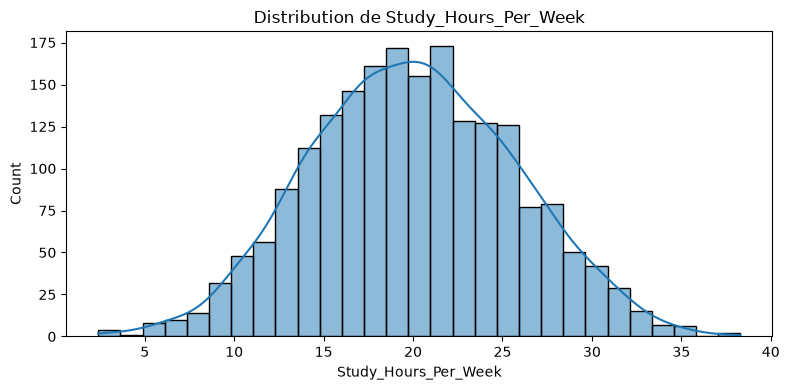

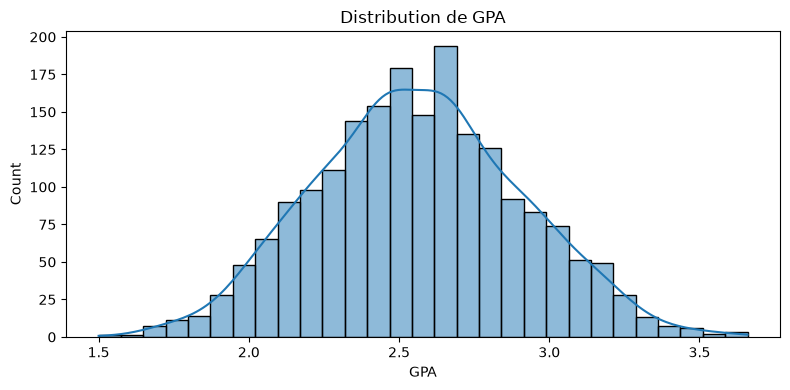

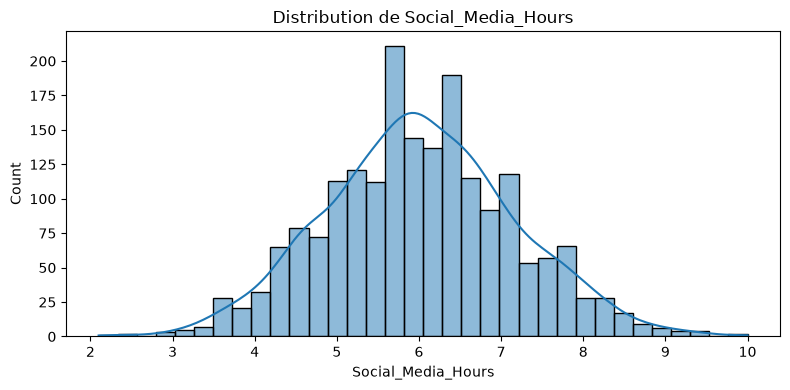

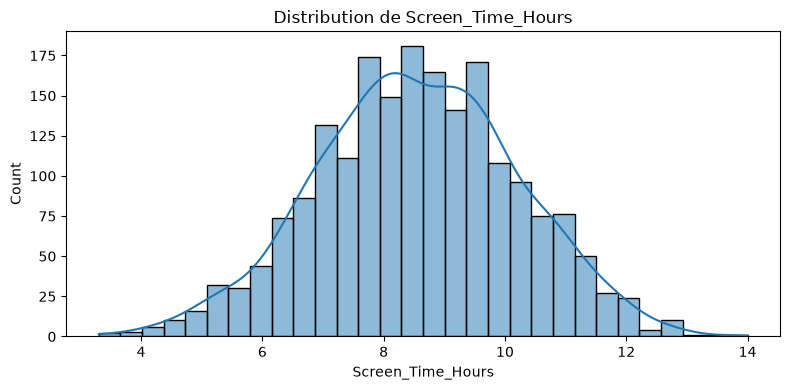

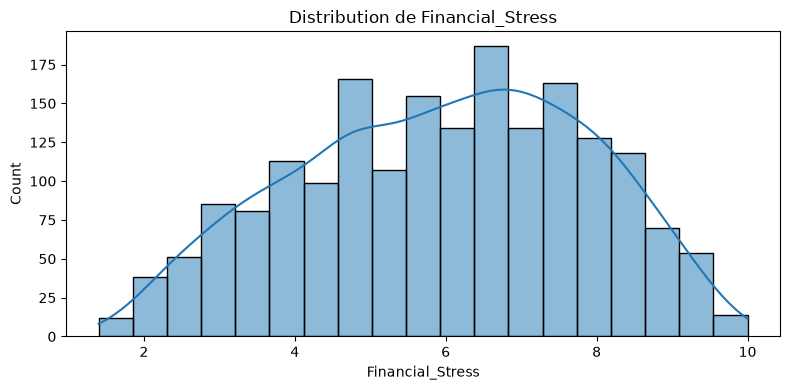

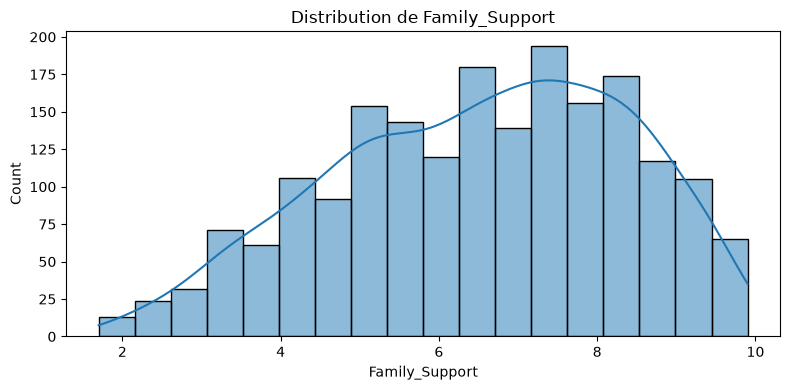

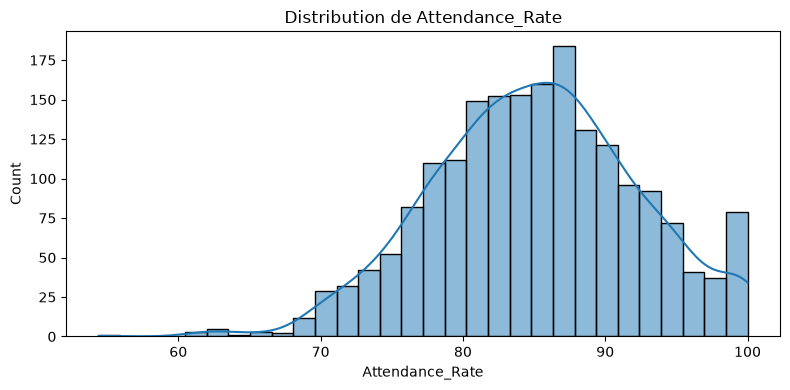

In [10]:
for column in numeric_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.title(f"Distribution de {column}")
    plt.tight_layout()
    plt.show()

la distribution des valeur discret 

In [11]:
discrete_columns = df[['Age', 'Year_of_Study']]
print("Variables discret  :", discrete_columns)

Variables discret  :       Age  Year_of_Study
0      22              3
1      21              4
2      22              5
3      24              1
4      20              1
...   ...            ...
1995   23              2
1996   21              2
1997   19              1
1998   21              3
1999   19              3

[2000 rows x 2 columns]


faire countplot pour les valeur discret 

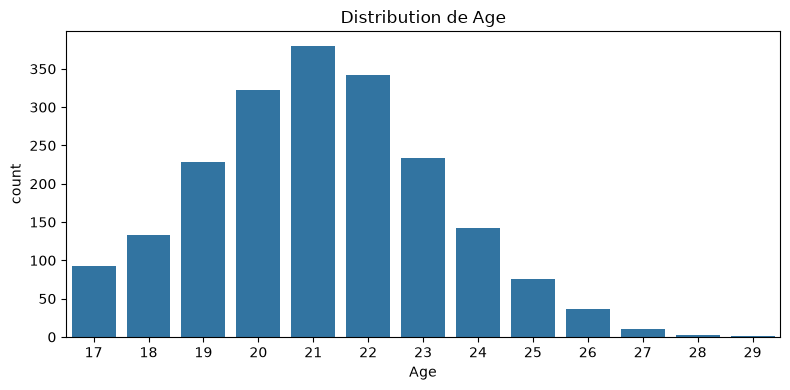

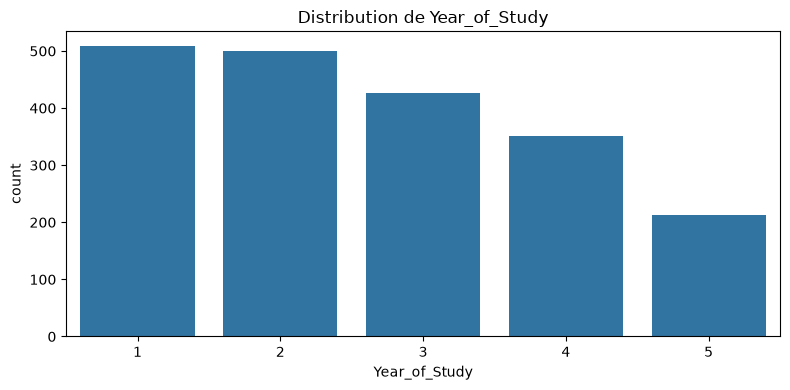

In [12]:
for column in discrete_columns:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=column,
        order=sorted(df[column].dropna().unique())
    )

    plt.title(f"Distribution de {column}")
    plt.tight_layout()
    plt.show()

la distribution des valeur categorielle 

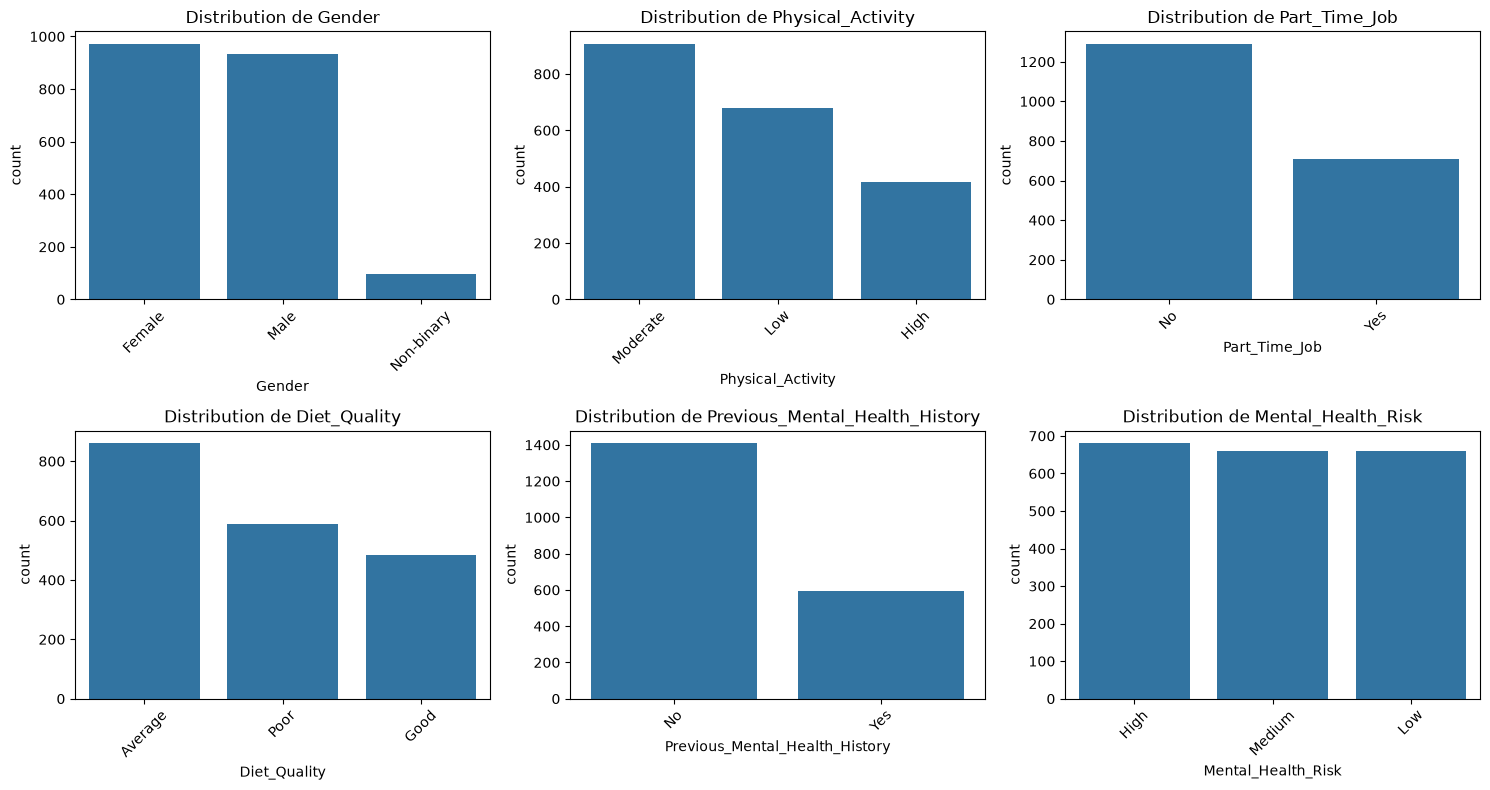

In [13]:


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    sns.countplot(data=df, x=column, order=df[column].value_counts().index, ax=ax)
    ax.set_title(f"Distribution de {column}")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

correlation

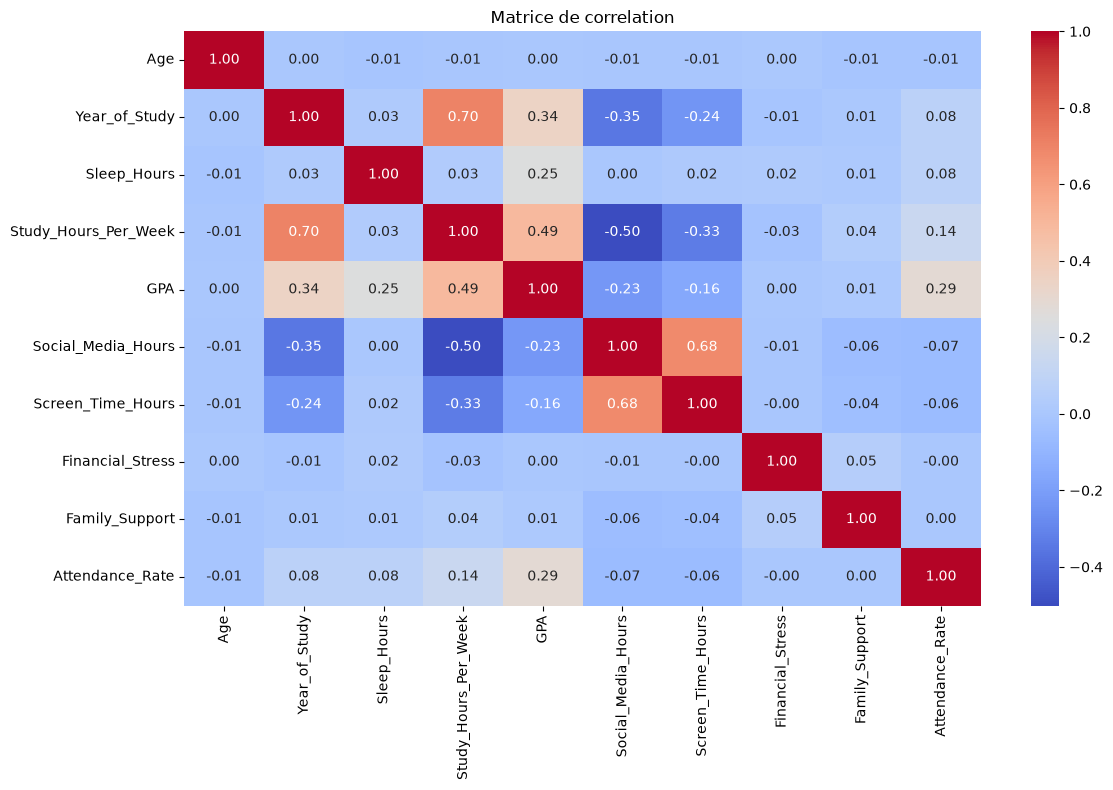

In [14]:

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

plt.title("Matrice de correlation")
plt.tight_layout()
plt.show()


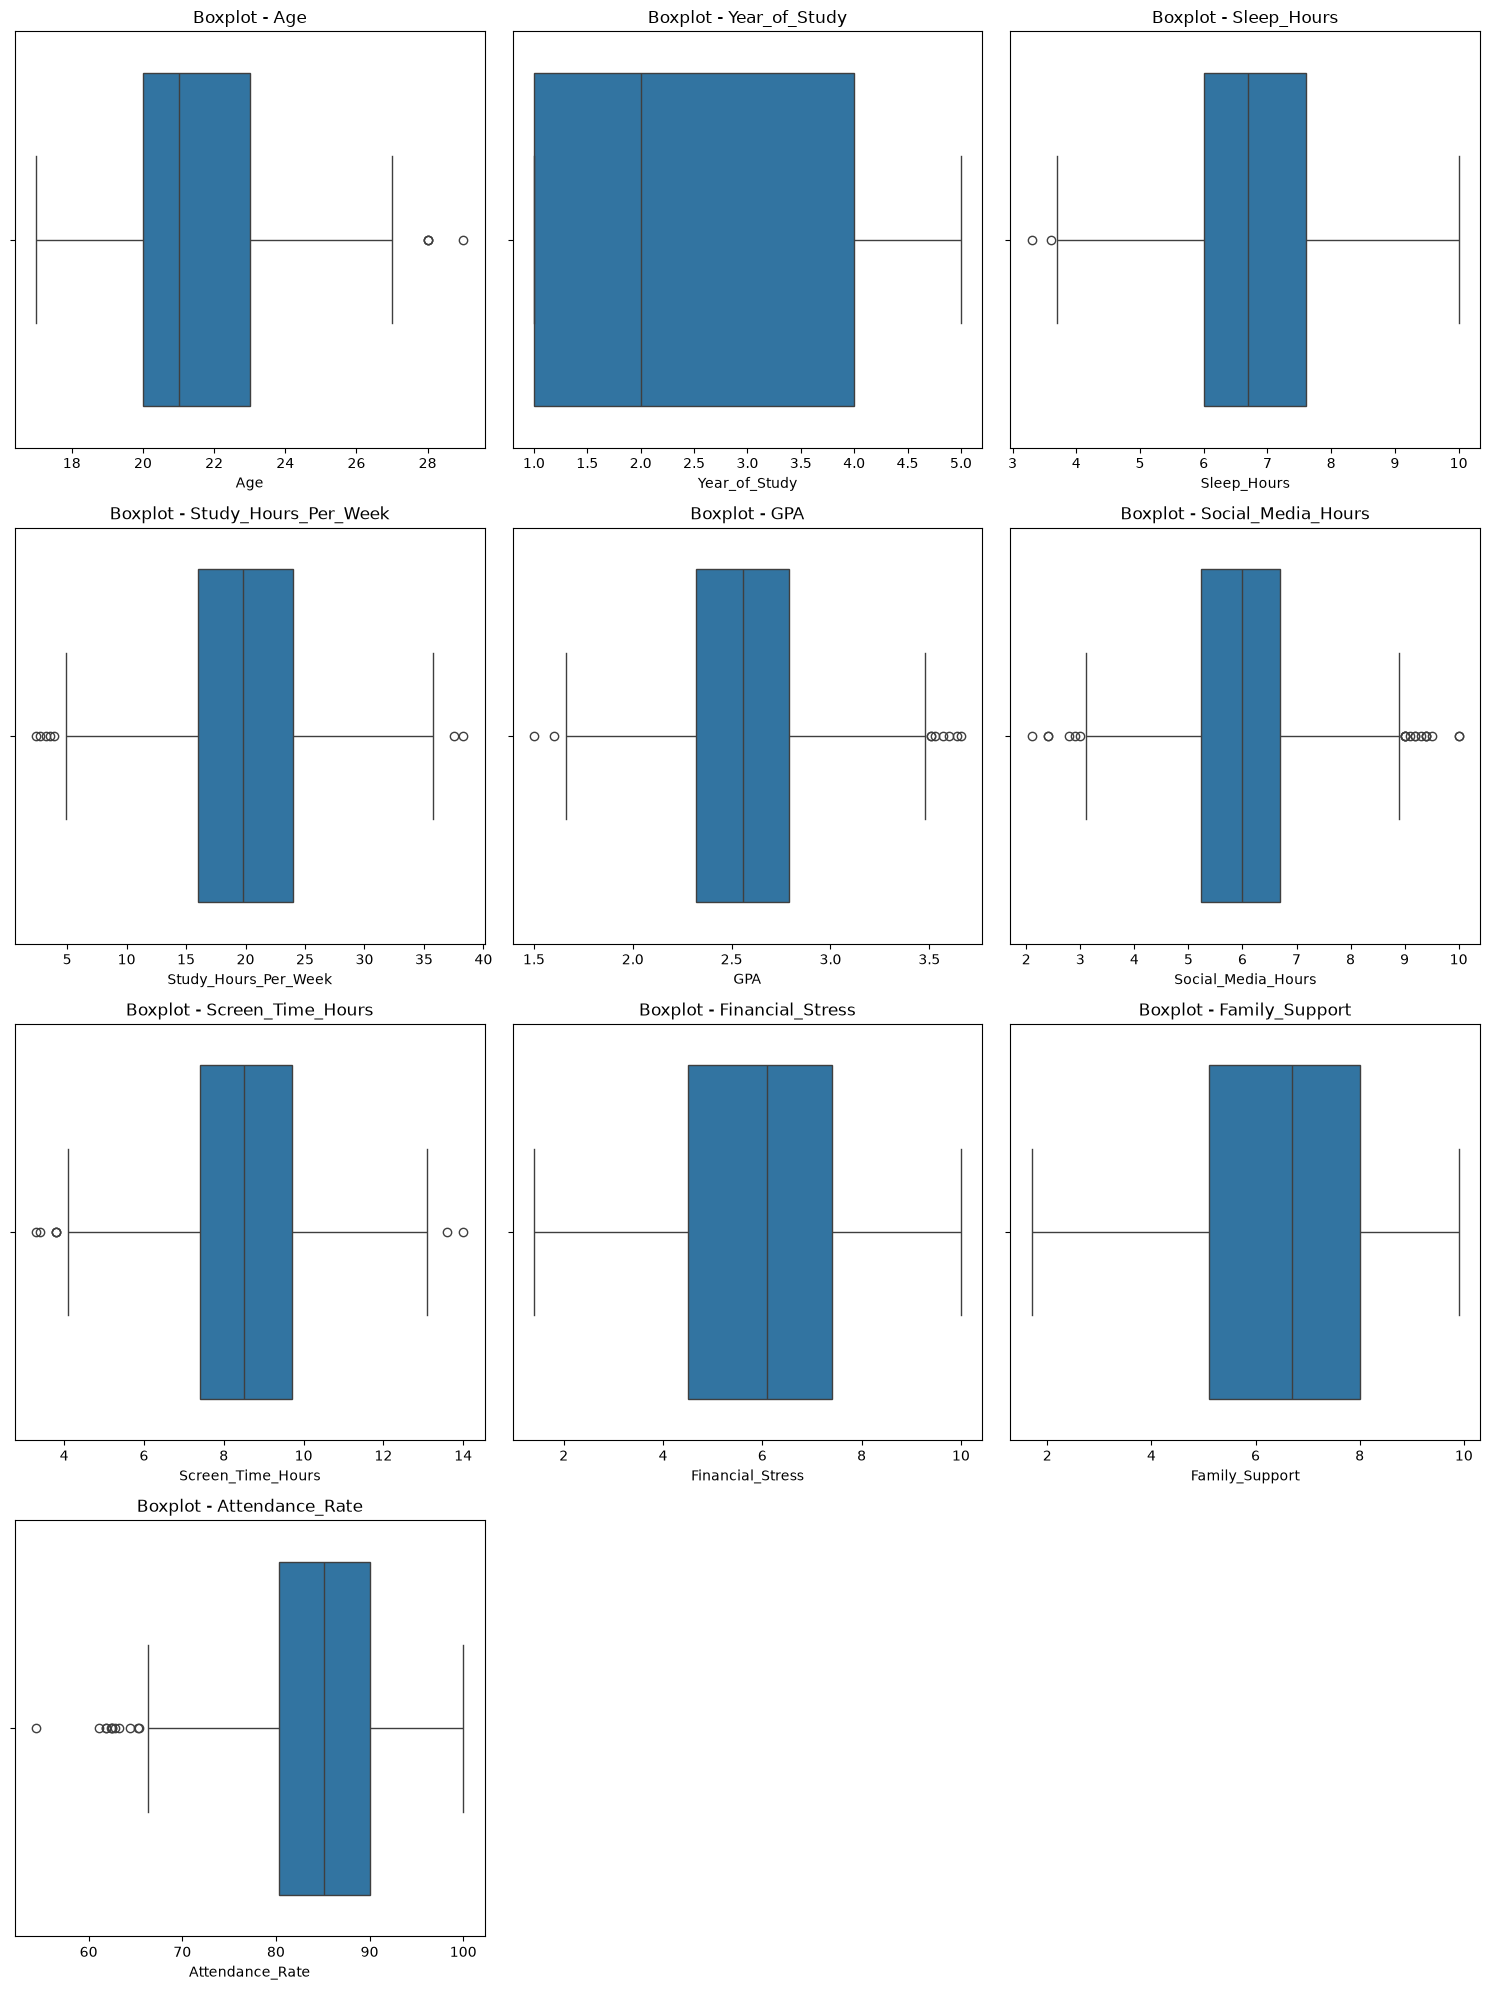

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n = len(numeric_columns)

n_cols = 3
n_rows = math.ceil(n / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))

axes = axes.flatten()

for i, column in enumerate(numeric_columns):

    sns.boxplot(data=df, x=column, ax=axes[i])

    axes[i].set_title(f"Boxplot - {column}")
    axes[i].set_xlabel(column)

# Supprimer les graphiques vides
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

traiter les valeur aberrante

In [16]:
outliers_summary = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outliers_summary.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers)
    })

outliers_df = pd.DataFrame(outliers_summary)

display(outliers_df)

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers Count
0,Age,20.000,23.00,3.000,15.5000,27.5000,4
1,Year_of_Study,1.000,4.00,3.000,-3.5000,8.5000,0
2,Sleep_Hours,6.000,7.60,1.600,3.6000,10.0000,2
3,Study_Hours_Per_Week,16.000,24.00,8.000,4.0000,36.0000,7
4,GPA,2.320,2.79,0.470,1.6150,3.4950,9
5,Social_Media_Hours,5.225,6.70,1.475,3.0125,8.9125,20
6,Screen_Time_Hours,7.400,9.70,2.300,3.9500,13.1500,7
7,Financial_Stress,4.500,7.40,2.900,0.1500,11.7500,0
8,Family_Support,5.100,8.00,2.900,0.7500,12.3500,0
9,Attendance_Rate,80.300,90.00,9.700,65.7500,104.5500,12


In [17]:
print(df["Age"][(df["Age"] < (df["Age"].quantile(0.25) - 1.5 * (df["Age"].quantile(0.75) - df["Age"].quantile(0.25)))) | (df["Age"] > (df["Age"].quantile(0.75) + 1.5 * (df["Age"].quantile(0.75) - df["Age"].quantile(0.25))))])

209     29
478     28
1615    28
1957    28
Name: Age, dtype: int64


separation des données

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Mental_Health_Risk"])
y = df["Mental_Health_Risk"]



Variables numeriques selon le niveau de risque

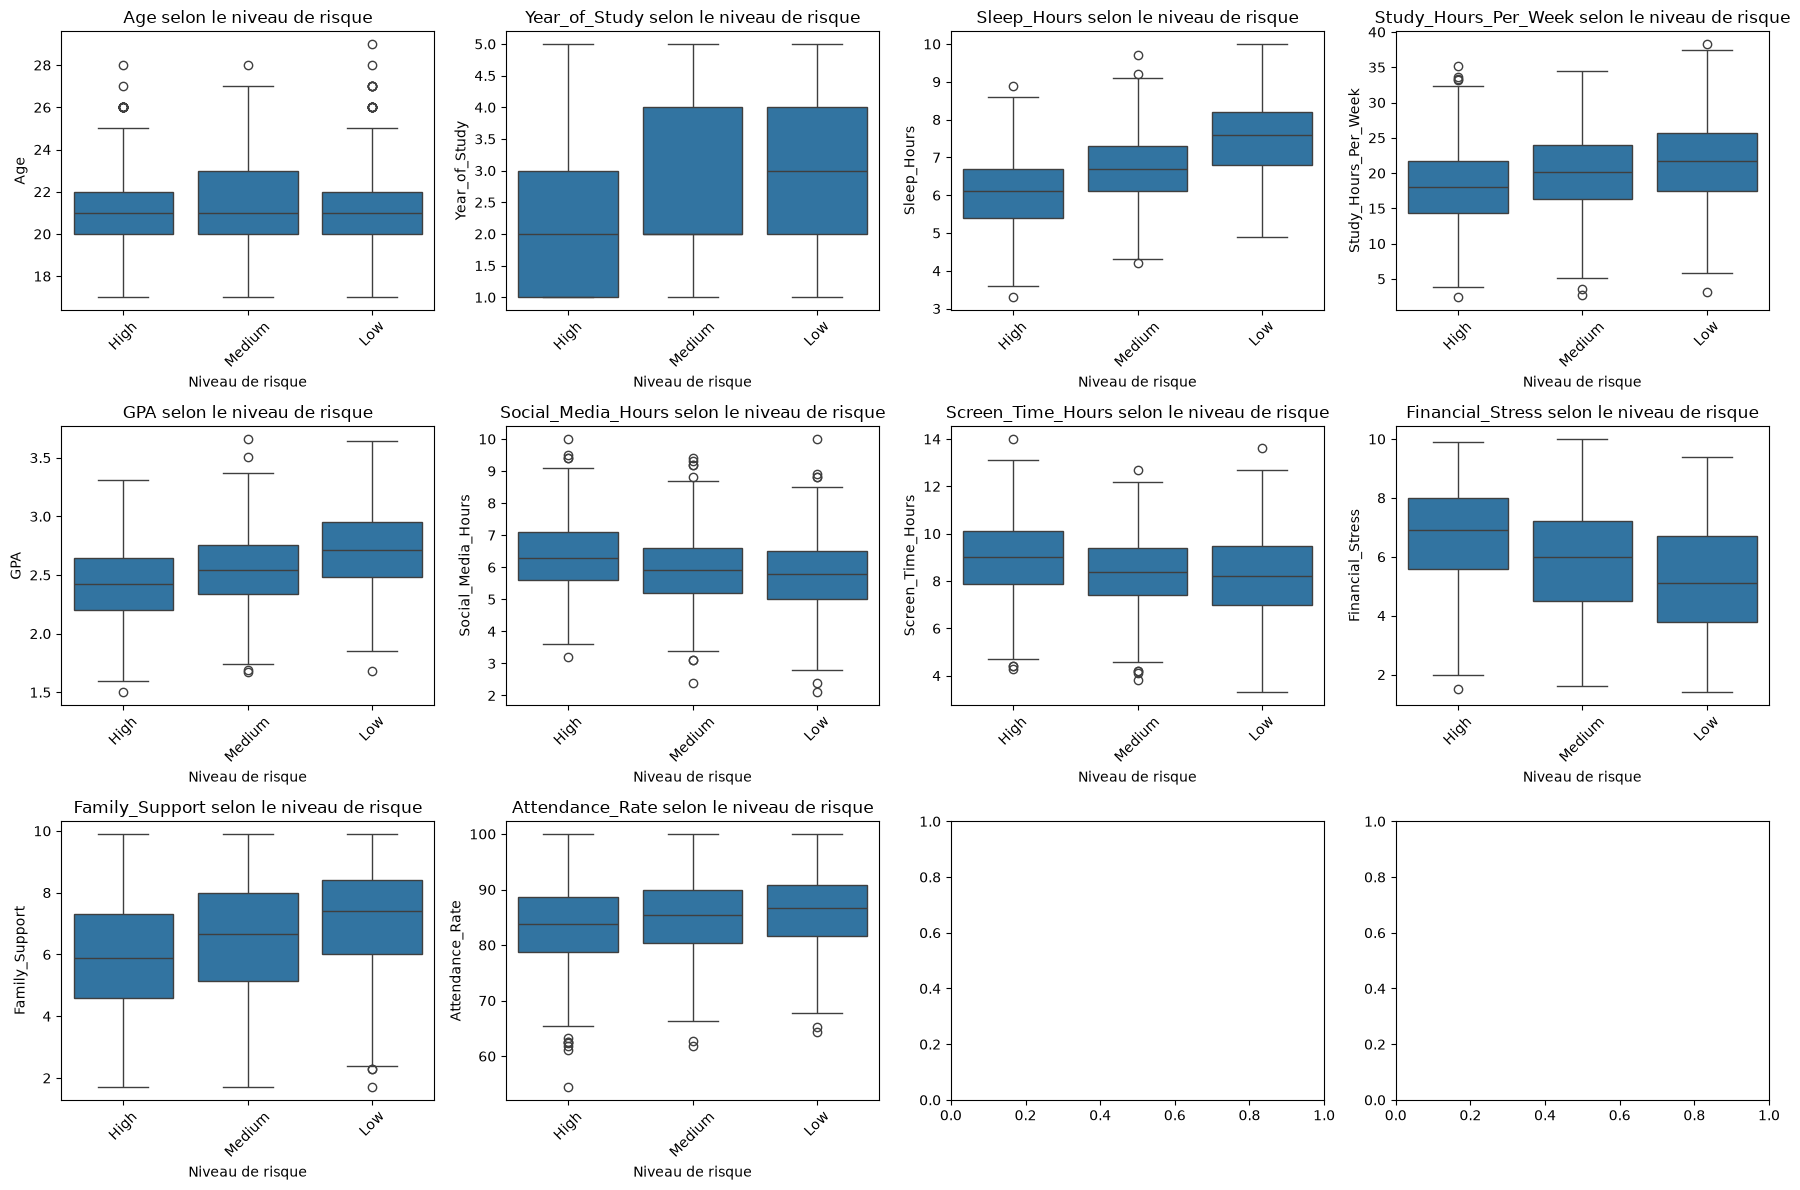

In [22]:



fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=df, x=y, y=column, ax=ax)
    ax.set_title(f"{column} selon le niveau de risque")
    ax.set_xlabel("Niveau de risque")
    ax.set_ylabel(column)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Variables categorielles selon le niveau de risque

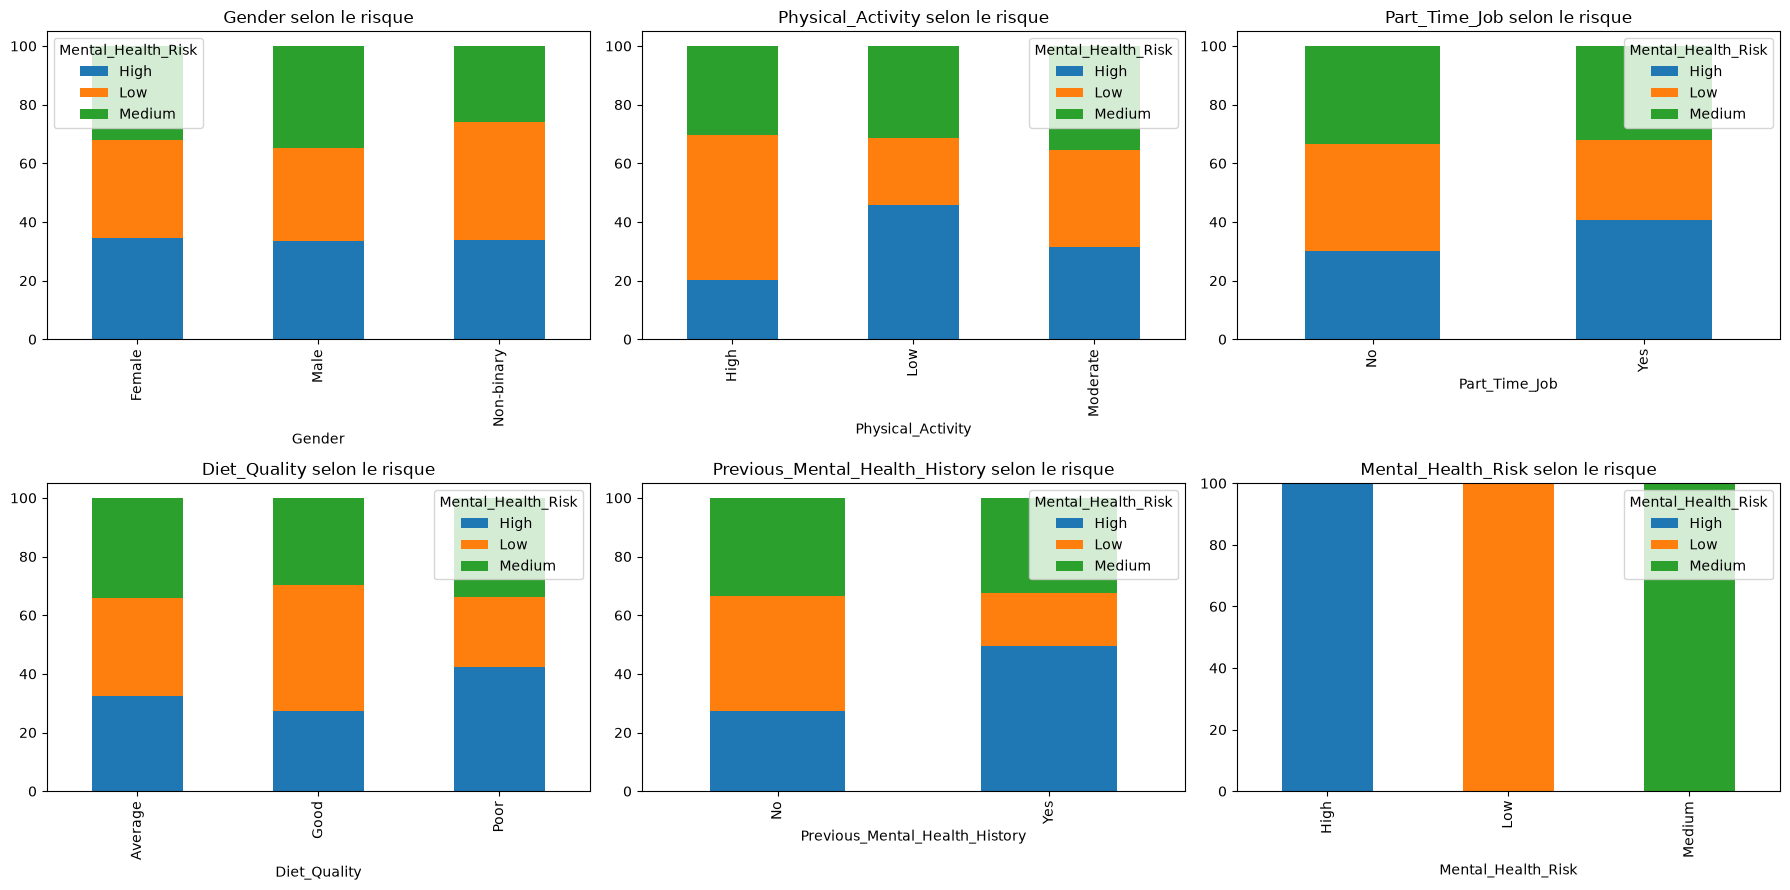

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
# categorical_features.remove('Student_ID')  
for ax, column in zip(axes, categorical_columns):
    cross_table = pd.crosstab(df[column], df["Mental_Health_Risk"], normalize="index") * 100
    cross_table.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{column} selon le risque")

plt.tight_layout()
plt.show()

visualisation avec barplot 

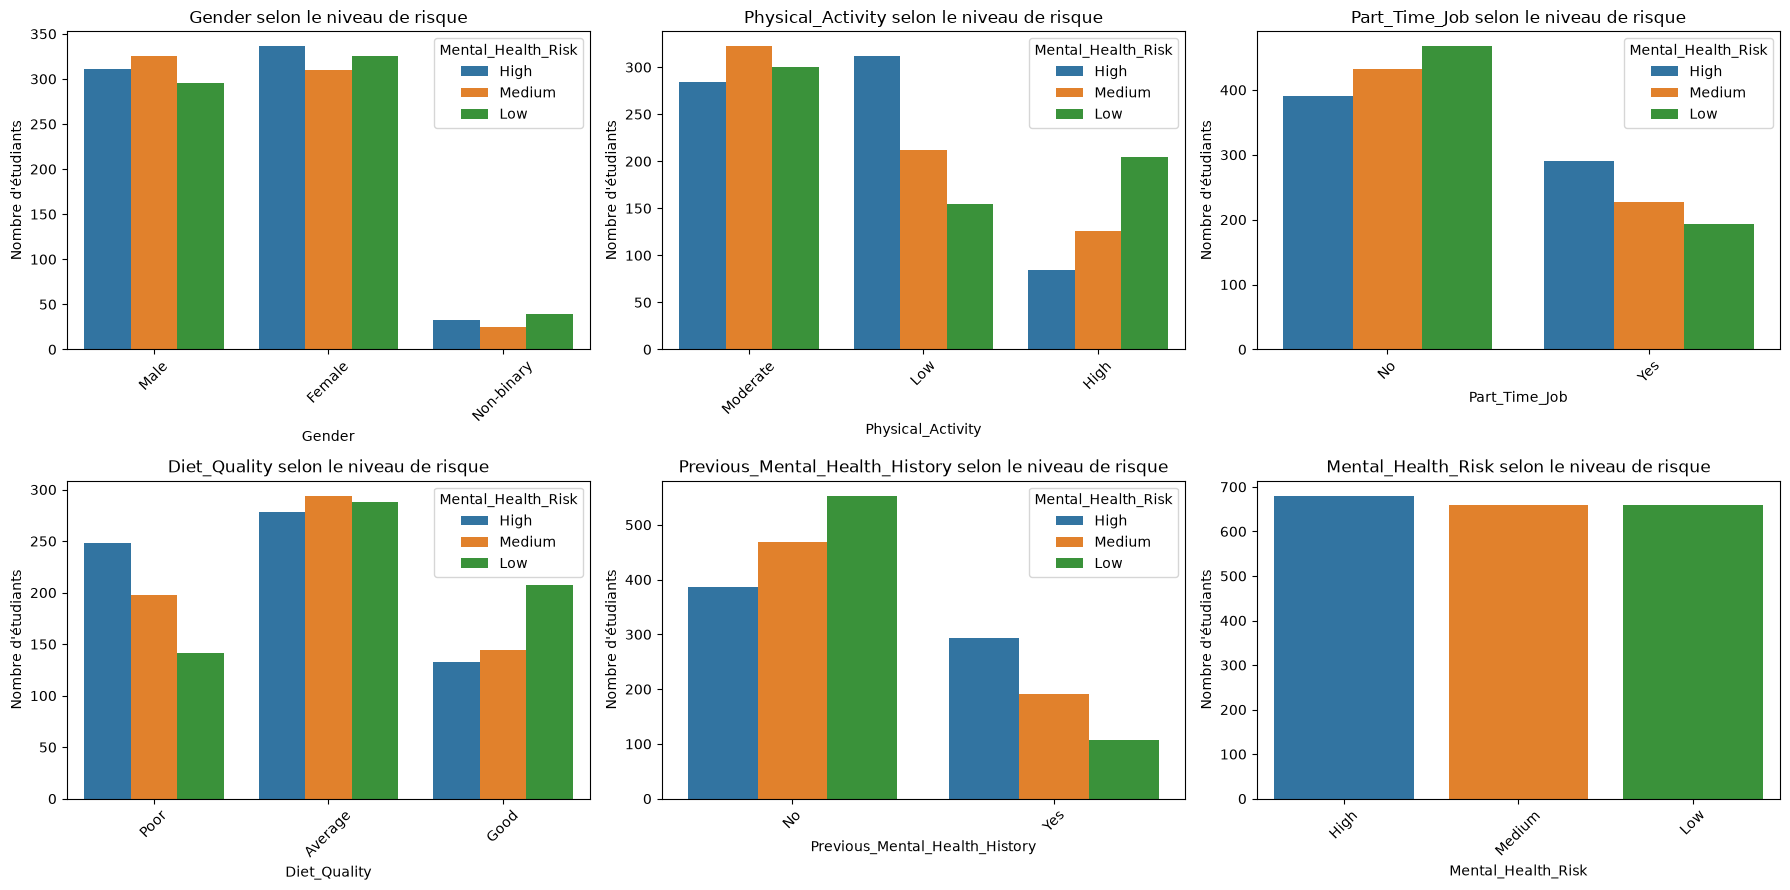

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    sns.countplot(data=df, x=column, hue=df["Mental_Health_Risk"], ax=ax)
    ax.set_title(f"{column} selon le niveau de risque")
    ax.set_ylabel("Nombre d'étudiants")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

etude le dequilibre des class 

In [26]:

class_counts = y.value_counts()
class_percentages = y.value_counts(normalize=True) * 100

class_distribution = pd.DataFrame({
    "Nombre d'observations": class_counts,
    "Pourcentage (%)": class_percentages.round(2)
})

display(class_distribution)

,Nombre d'observations,Pourcentage (%)
Mental_Health_Risk,,
High,680,34.0
Medium,660,33.0
Low,660,33.0


split data 

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

definire le preprocessing

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Variables num :", numeric_features)
print("Variables cat :", categorical_features)

Variables num : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Variables cat : ['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\Youcode\AppData\Local\Temp\ipykernel_33564\3121000158.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


partie entrainement

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

print("Nombre de modèles :", len(models))

Nombre de modèles : 3


entrainer et comparer le modeles 

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
results = []
trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

    trained_models[model_name] = pipeline

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.7200,0.726602,0.7200,0.722712
1,Random Forest,0.6225,0.618171,0.6225,0.619585
2,KNN,0.5550,0.542882,0.5550,0.546935


matrice de confusion

optimisation et evaluation de final 

In [31]:
best_model_name = results_df.sort_values(
    by="F1-score",
    ascending=False
).iloc[0]["Model"]

print("Modele selectionee :", best_model_name)

best_pipeline = trained_models[best_model_name]

Modele selectionee : Logistic Regression


matrice confusion

In [32]:
yred_best = best_pipeline.predict(X_test)

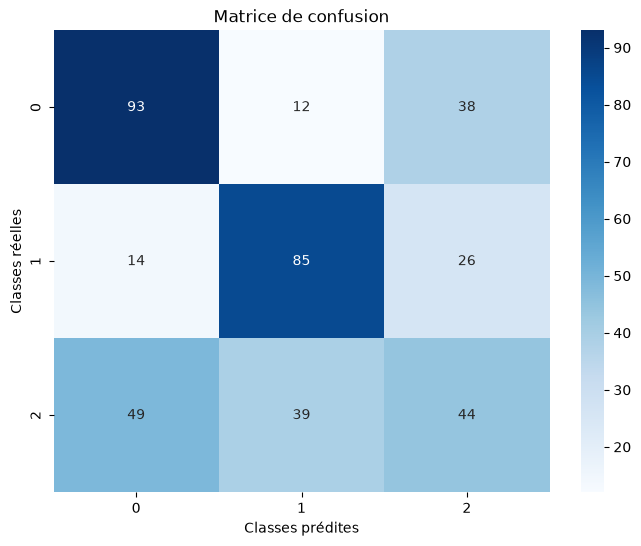

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Matrice de confusion")
plt.xlabel("Classes prédites")
plt.ylabel("Classes réelles")

plt.show()

la partie gridsearch et crosse validation 

In [34]:
from sklearn.model_selection import GridSearchCV ,StratifiedKFold
cv =StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring="f1_macro"

definir pipline des model avec preprocessing

In [47]:
pipe={
    "Logistique_Regression":   Pipeline([
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(max_iter=1000,random_state=42))
    ]),
    "KNN": Pipeline([
        ("preprocessor",preprocessor),
        ("classifier",KNeighborsClassifier(n_neighbors=5))
    ]),
   "Random Forest": Pipeline([
        ("preprocessor",preprocessor),
        ("classifier",RandomForestClassifier(random_state=42))])
}

definir les paramatere a faire grid search 

In [54]:
param_grid={
    "Logistique_Regression": { "classifier__C": [0.1, 1, 10]},
    "KNN":{ "classifier__n_neighbors": [3, 5, 7, 9, 11],"classifier__weights": ["uniform", "distance"],"classifier__p": [1, 2]},
    "Random Forest": {"classifier__n_estimators": [50, 100, 200],"classifier__max_depth": [None, 10, 20],"classifier__min_samples_split": [2, 5]}
        }

lancement gread search 

In [55]:

best_models = {}
optimization_results = []

for name, model_pipe in pipe.items():
    grid_search = GridSearchCV(
        estimator=model_pipe,
        param_grid=param_grid[name],
        scoring=scoring,
        cv=cv,
        n_jobs=-1,
    )
    grid_search.fit(X_train, y_train)
    best_models[name] = grid_search.best_estimator_
    optimization_results.append({
        "Model": name,
        "Best Parameters": grid_search.best_params_,
        "Best Score": grid_search.best_score_,
    })

comparer les models 

In [63]:
optimization_df = pd.DataFrame(optimization_results)

optimization_df = optimization_df.sort_values(
    by="Best Score",
    ascending=False
)

display(optimization_df)

,Model,Best Parameters,Best Score
0,Logistique_Regression,{'classifier__C': 1},0.761774
2,Random Forest,"{'classifier__max_depth': 20, 'classifier__min...",0.679629
1,KNN,"{'classifier__n_neighbors': 11, 'classifier__p...",0.639019


choisir meilleru model 

In [ ]:
best_model_name = optimization_df.iloc[0]["Model"]

best_model = best_models[best_model_name]

print("Meilleur modèle :", best_model_name)
print("F1-macro en validation corise:",
      round(optimization_df.iloc[0]["Best Score"], 3))

Meilleur modèle : Logistique_Regression
F1-macro en validation croisée : 0.762


faire une predicton

In [65]:
y_pred = best_model.predict(X_test)

calculer les metrique 

In [67]:
from sklearn.metrics import (
  
    classification_report
)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))
    


              precision    recall  f1-score   support

        High       0.83      0.78      0.81       143
         Low       0.77      0.75      0.76       125
      Medium       0.57      0.62      0.60       132

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.73      0.72      0.72       400



afficher matrice de confusion 

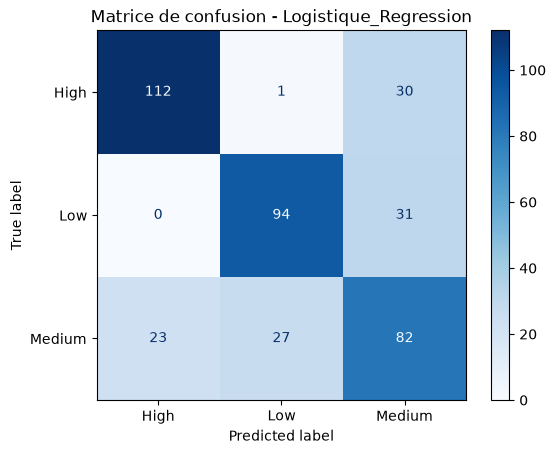

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title(f"Matrice de confusion - {best_model_name}")
plt.show()

sauvegard model joblib

In [73]:
import joblib
from pathlib import Path

PROJECT_ROOT=Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "artifacts/models"

model_path = MODEL_DIR / "best_mental_health_model.joblib"
joblib.dump(best_model, model_path)

print("Modèle sauvegardé :", model_path)

Modèle sauvegardé : c:\Users\Youcode\Desktop\2eme année IA\projet_soutenance_croisée\artifacts\models\best_mental_health_model.joblib


dowlond the model

In [ ]:
loaded_model = joblib.load(model_path)


new_predictions = loaded_model.predict(X_test.head(5))

print(new_predictions)

['Medium' 'Medium' 'Medium' 'Low' 'Medium']
